# KDE-BDPC on Reacher: fixed-seed tuning audit

This report replaces the previous displayed results. It recomputes tables and plots from saved experiment traces; **no controller or new sweep is run**.

**Main diagnostic: seed 211, 300 controlled steps.** Every saved tuning setting on this seed is shown, including incomplete attempts. The seed is a development diagnostic, not a held-out performance estimate. Change `FOCUS_SEED` below to inspect another saved seed.

Historical screens with other seeds and the separate 100-seed development panel appear later. The original data remain unchanged on Crucial X10. KDE–Atlas hybrid trials are excluded because they use a different controller. This is an audit of available saved records, not a claim to reconstruct unrecorded manual trials.

## Implementation and interpretation

- Same 200 offline Reacher episodes as Atlas; MVC groups whole episodes using two-view joint NMF. Length-12 segments are standardized, clustered, mean-centered and represented by SVD bases.
- Gaussian KDE uses all cluster segments; membership-weighted projector interpolation selects the online dimension. Intermediate references come from minimum-mean-entropy graph routing.
- The control objective uses squared trajectory tracking and squared past-input/output mismatch, with a coefficient-radius constraint. Clarabel; physical input clipping is recorded. No Atlas controller is used.
- **Multistep adaptation:** interpolation uses 12 measured samples; control matches the latest two and predicts ten, applying only the first action. This is not a claim that the paper specifies these horizons.
- Historical KDE-BDPC runs retain their recorded finite simple-path search cap. The newer route solver used in the hybrid is not retroactively attributed to these results. Search-cap aborts are implementation/computational outcomes, not evidence of a violated theoretical assumption.
- A completed rollout succeeds only when both final-30 and final-100 windows have mean error <10 mm and maximum error <20 mm. Offline rejection, planning/solver abort, and completed tracking failure are reported separately.
- Accepted-step computation time includes membership, interpolation, online connections/routing, matrix preparation and optimization. It excludes offline work, warmup, simulator stepping and disk I/O. Failed-attempt durations remain in the failure records.

Values below are **observed attempts**, not a full Cartesian grid. Screens used different seed sets; the notebook exposes these sets and does not pool their success rates into one performance claim.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents,
                       Path('/Users/kumiko/Projects/atlas_deepc/code')]
            if (p/'src/comparison_methods/kde_bdpc/effort.py').is_file())
sys.path.insert(0, str(ROOT/'src'))
from comparison_methods.kde_bdpc import effort

FOCUS_SEED = 211
EXPERIMENT_ROOT = Path('/Volumes/Crucial X10/atlas_deepc_data/experiments/reacher')
report, measurements = effort.scan(EXPERIMENT_ROOT)
candidate_rows = [r for r in report['configurations'] if r['group']=='tuning']
config_by_name = {r['candidate']:r for r in report['configurations']}
focus = [dict(r) for r in report['rollouts']
         if r['group']=='tuning' and r['seed']==FOCUS_SEED]
if not focus:
    raise ValueError(f'No saved tuning traces for seed {FOCUS_SEED}')
for row in focus:
    start, stop = measurements['rollout_offsets'][row['rollout_id']:row['rollout_id']+2]
    errors = measurements['distance_m'][start:stop]*1000
    pred = measurements['prediction_error_xy_m'][start:stop]*1000
    row['final30_mean_mm'] = float(errors[-30:].mean()) if row['success_evaluable'] else np.nan
    row['final30_max_mm'] = float(errors[-30:].max()) if row['success_evaluable'] else np.nan
    row['median_prediction_mm'] = float(np.median(pred[np.isfinite(pred)])) if np.isfinite(pred).any() else np.nan
    row['name'] = row['candidate'].split('/')[-1]
    row['outcome'] = ('Success' if row['strict_success'] else
                      'Completed: tracking failure' if row['complete'] else 'Aborted / incomplete')
focus.sort(key=lambda r: (not r['complete'],
                         r['mean_final100_error_mm'] if r['mean_final100_error_mm'] is not None else np.inf,
                         r['candidate']))
plt.rcParams.update({'font.size':10, 'axes.spines.top':False, 'axes.spines.right':False,
                     'axes.grid':True, 'grid.alpha':0.2, 'figure.dpi':120})
print('Saved experiment source:', EXPERIMENT_ROOT)
print('Read-only report: no simulation, tuning, or external-drive writes.')

Saved experiment source: /Volumes/Crucial X10/atlas_deepc_data/experiments/reacher
Read-only report: no simulation, tuning, or external-drive writes.


## 1. Fixed-seed result at a glance

The four success conditions are mean error below 10 mm and maximum error below 20 mm over **each** of the final 30 and final 100 steps. An aborted attempt is not a completed tracking failure. A low value in one error column alone does not establish success.

In [2]:
unique_configs = len({json.dumps(config_by_name[r['candidate']]['config'],sort_keys=True) for r in focus})
complete = [r for r in focus if r['complete']]
successes = sum(r['strict_success'] for r in focus)
display(pd.DataFrame([{
    'Development seed': FOCUS_SEED, 'Saved attempts':len(focus),
    'Distinct configurations':unique_configs, 'Completed':len(complete),
    'Aborted / incomplete':len(focus)-len(complete), 'Successful':successes,
    'Recorded horizons':str(sorted({r['requested_steps'] for r in focus}))
}]))
if successes == 0:
    display(Markdown(f'**None of the {len(focus)} saved tuning attempts on seed {FOCUS_SEED} met the success criterion.** '
                     f'{len(complete)} completed their recorded horizons; {len(focus)-len(complete)} aborted or were incomplete.'))
else:
    display(Markdown(f'**{successes} saved attempts met the success criterion on seed {FOCUS_SEED}.**'))
if complete:
    best = complete[0]
    display(Markdown(f"Lowest final-100 mean error among completed attempts: **{best['name']}**, "
                     f"**{best['mean_final100_error_mm']:.2f} mm**. This is a development-only descriptive ranking, not a validated best controller."))

,Development seed,Saved attempts,Distinct configurations,Completed,Aborted / incomplete,Successful,Recorded horizons
0,211,39,38,37,2,0,[300]


**None of the 39 saved tuning attempts on seed 211 met the success criterion.** 37 completed their recorded horizons; 2 aborted or were incomplete.

Lowest final-100 mean error among completed attempts: **k4_subspace_consensus**, **41.54 mm**. This is a development-only descriptive ranking, not a validated best controller.

## 2. Hyperparameters actually tested on this seed

These are observed parameter values, **not** a Cartesian grid. The complete configuration table preserves the tested combinations. “Completed values” excludes settings for which no full rollout finished on this seed. Requested and active cluster counts are reported separately.

In [3]:
range_rows = []
for key, meaning in effort.PARAMETERS.items():
    attempted = sorted({config_by_name[r['candidate']]['config'][key] for r in focus})
    completed = sorted({config_by_name[r['candidate']]['config'][key] for r in complete})
    range_rows.append({'Parameter':key,'Meaning':meaning,
                      'Attempted values':', '.join(f'{v:g}' for v in attempted),
                      'Completed values':', '.join(f'{v:g}' for v in completed)})
with pd.option_context('display.max_rows',None,'display.max_colwidth',150):
    display(pd.DataFrame(range_rows))
configuration_table = pd.DataFrame([{
    'Candidate':r['candidate'], **{key:config_by_name[r['candidate']]['config'][key] for key in effort.PARAMETERS},
    'Active K':config_by_name[r['candidate']]['active_clusters'], 'Outcome':r['outcome']
} for r in focus])
with pd.option_context('display.max_rows',None,'display.max_columns',None,'display.max_colwidth',100):
    display(configuration_table)

,Parameter,Meaning,Attempted values,Completed values
0,clusters,Requested cluster count K,"2, 3, 4, 5, 6, 8, 12, 16","2, 3, 4, 5, 6, 8"
1,nmf_seed,NMF initialization seed,"7, 42","7, 42"
2,lambda_view1,"MVC consensus penalty, view 1","0.01, 0.1","0.01, 0.1"
3,lambda_view2,"MVC consensus penalty, view 2","0.1, 1","0.1, 1"
4,svd_rtol,Relative offline SVD cutoff,"0.01, 0.03, 0.1, 0.2","0.01, 0.03, 0.1, 0.2"
5,beta_kde,KDE covariance multiplier,"0.3, 1.5, 5, 20","0.3, 1.5, 5, 20"
6,beta_bound,Local-step / coefficient radius,"1, 2, 5, 20","1, 2, 5, 20"
7,beta_s,Connection density-ratio threshold,0.8,0.8
8,lambda_epsilon,Past-mismatch penalty,"100, 1000, 10000, 100000, 1e+06","100, 1000, 10000, 100000, 1e+06"
9,q_joint,Joint-output tracking weight,"4, 40, 400, 4000","4, 40, 400, 4000"


,Candidate,clusters,nmf_seed,lambda_view1,lambda_view2,svd_rtol,beta_kde,beta_bound,beta_s,lambda_epsilon,q_joint,q_dq,q_xy,r,Active K,Outcome
0,kde_bdpc_cluster_tuning_20261101_v1/k4_subspace_consensus,4,42,0.01,1.0,0.01,1.5,5.0,0.8,100.0,4000.0,100.0,400.0,0.1,4,Completed: tracking failure
1,kde_bdpc_tuning_20261101_v1/baseline,5,42,0.10,0.1,0.01,1.5,1.0,0.8,100.0,4000.0,100.0,400.0,0.1,5,Completed: tracking failure
2,kde_bdpc_tuning_20261101_v1/default,5,42,0.10,0.1,0.01,1.5,1.0,0.8,100.0,4000.0,100.0,400.0,0.1,5,Completed: tracking failure
3,kde_bdpc_tuning_20261101_v1/radius5,5,42,0.10,0.1,0.01,1.5,5.0,0.8,100.0,4000.0,100.0,400.0,0.1,5,Completed: tracking failure
4,kde_bdpc_cluster_tuning_20261101_v1/k4_consensus_radius2,4,42,0.01,1.0,0.01,1.5,2.0,0.8,100.0,4000.0,100.0,400.0,0.1,4,Completed: tracking failure
5,kde_bdpc_cluster_tuning_20261101_v1/k4_consensus_damped,4,42,0.01,1.0,0.01,1.5,5.0,0.8,1000.0,4000.0,1000.0,400.0,0.1,4,Completed: tracking failure
6,kde_bdpc_tuning_20261101_v1/moderate,5,42,0.10,0.1,0.01,1.5,2.0,0.8,1000.0,4000.0,1000.0,400.0,1.0,5,Completed: tracking failure
7,kde_bdpc_tuning_20261101_v1/small_step_eps1e5,5,42,0.10,0.1,0.01,1.5,1.0,0.8,100000.0,4000.0,100.0,400.0,0.1,5,Completed: tracking failure
8,kde_bdpc_tuning_20261101_v1/balanced,5,42,0.10,0.1,0.01,1.5,5.0,0.8,100000.0,400.0,10.0,400.0,0.1,5,Completed: tracking failure
9,kde_bdpc_tuning_20261101_v1/svd01_small,5,42,0.10,0.1,0.10,1.5,1.0,0.8,100000.0,4000.0,100.0,400.0,0.1,5,Completed: tracking failure


## 3. Every saved attempt: errors, timing, and abort reasons

Rows are sorted by completed status and final-100 mean error. All four terminal-window statistics are displayed. Timing is the median over accepted online steps in each attempt, not the time of a failed solver/planner call; failed-call information is retained in the abort table. One-step prediction error, where recorded, measures fingertip prediction mismatch rather than target tracking error.

In [4]:
fixed_results = pd.DataFrame([{
    'Candidate':r['name'], 'Outcome':r['outcome'],
    'Steps':f"{r['completed_steps']}/{r['requested_steps']}",
    'Final-30 mean (mm)':r['final30_mean_mm'], 'Final-30 max (mm)':r['final30_max_mm'],
    'Final-100 mean (mm)':r['mean_final100_error_mm'], 'Final-100 max (mm)':r['max_final100_error_mm'],
    'Median time (ms)':r['median_online_ms'], 'Median prediction error (mm)':r['median_prediction_mm']
} for r in focus])
with pd.option_context('display.max_rows',None,'display.max_columns',None):
    display(fixed_results.round(3))
abort_rows = [{'Candidate':r['candidate'],'Completed steps':r['completed_steps'],
               'Recorded failure':json.dumps(r['failure'],sort_keys=True)}
              for r in focus if not r['complete']]
if abort_rows:
    with pd.option_context('display.max_colwidth',None):
        display(pd.DataFrame(abort_rows))
print(report['timing_definition'])

,Candidate,Outcome,Steps,Final-30 mean (mm),Final-30 max (mm),Final-100 mean (mm),Final-100 max (mm),Median time (ms),Median prediction error (mm)
0,k4_subspace_consensus,Completed: tracking failure,300/300,49.609,50.390,41.535,50.390,47.765,31.019
1,baseline,Completed: tracking failure,300/300,56.040,56.851,54.358,56.851,40.148,1.123
2,default,Completed: tracking failure,300/300,56.040,56.851,54.358,56.851,39.252,1.123
3,radius5,Completed: tracking failure,300/300,81.685,89.327,59.763,89.327,41.540,34.122
4,k4_consensus_radius2,Completed: tracking failure,300/300,67.896,69.753,63.341,69.753,39.367,2.895
5,k4_consensus_damped,Completed: tracking failure,300/300,63.677,72.115,69.440,82.389,43.519,41.721
6,moderate,Completed: tracking failure,300/300,194.367,253.242,98.327,253.242,48.050,4.439
7,small_step_eps1e5,Completed: tracking failure,300/300,211.113,229.963,135.033,229.963,76.847,7.447
8,balanced,Completed: tracking failure,300/300,184.045,191.587,147.822,191.587,75.924,20.430
9,svd01_small,Completed: tracking failure,300/300,156.802,161.371,161.852,175.934,68.911,3.275


,Candidate,Completed steps,Recorded failure
0,kde_bdpc_cluster_tuning_20261101_v1/k12_radius5,0,"{""attempt_compute_time_s"": 0.17836712498683482, ""message"": ""Exact simple-path search budget exceeded"", ""step"": 0}"
1,kde_bdpc_cluster_tuning_20261101_v1/k16_radius5,0,"{""attempt_compute_time_s"": 0.23107658300432377, ""message"": ""Exact simple-path search budget exceeded"", ""step"": 0}"


Measured accepted online steps: membership, interpolation, online graph construction/search, matrix preparation and optimization. Excludes offline work, warmup, simulation and disk I/O. Median pools steps within a candidate; failed-attempt timing is in each rollout failure record.


## 4. Fixed-seed visual summary

The top panels show every attempt. The lower panels show all saved traces in gray and highlight the three completed attempts with the smallest final-100 mean errors. The ranking rule is explicit and the gray curves retain the remaining evidence. Dashed error thresholds are window-mean/max criteria, not pointwise success labels. Incomplete traces stop at their last saved step.

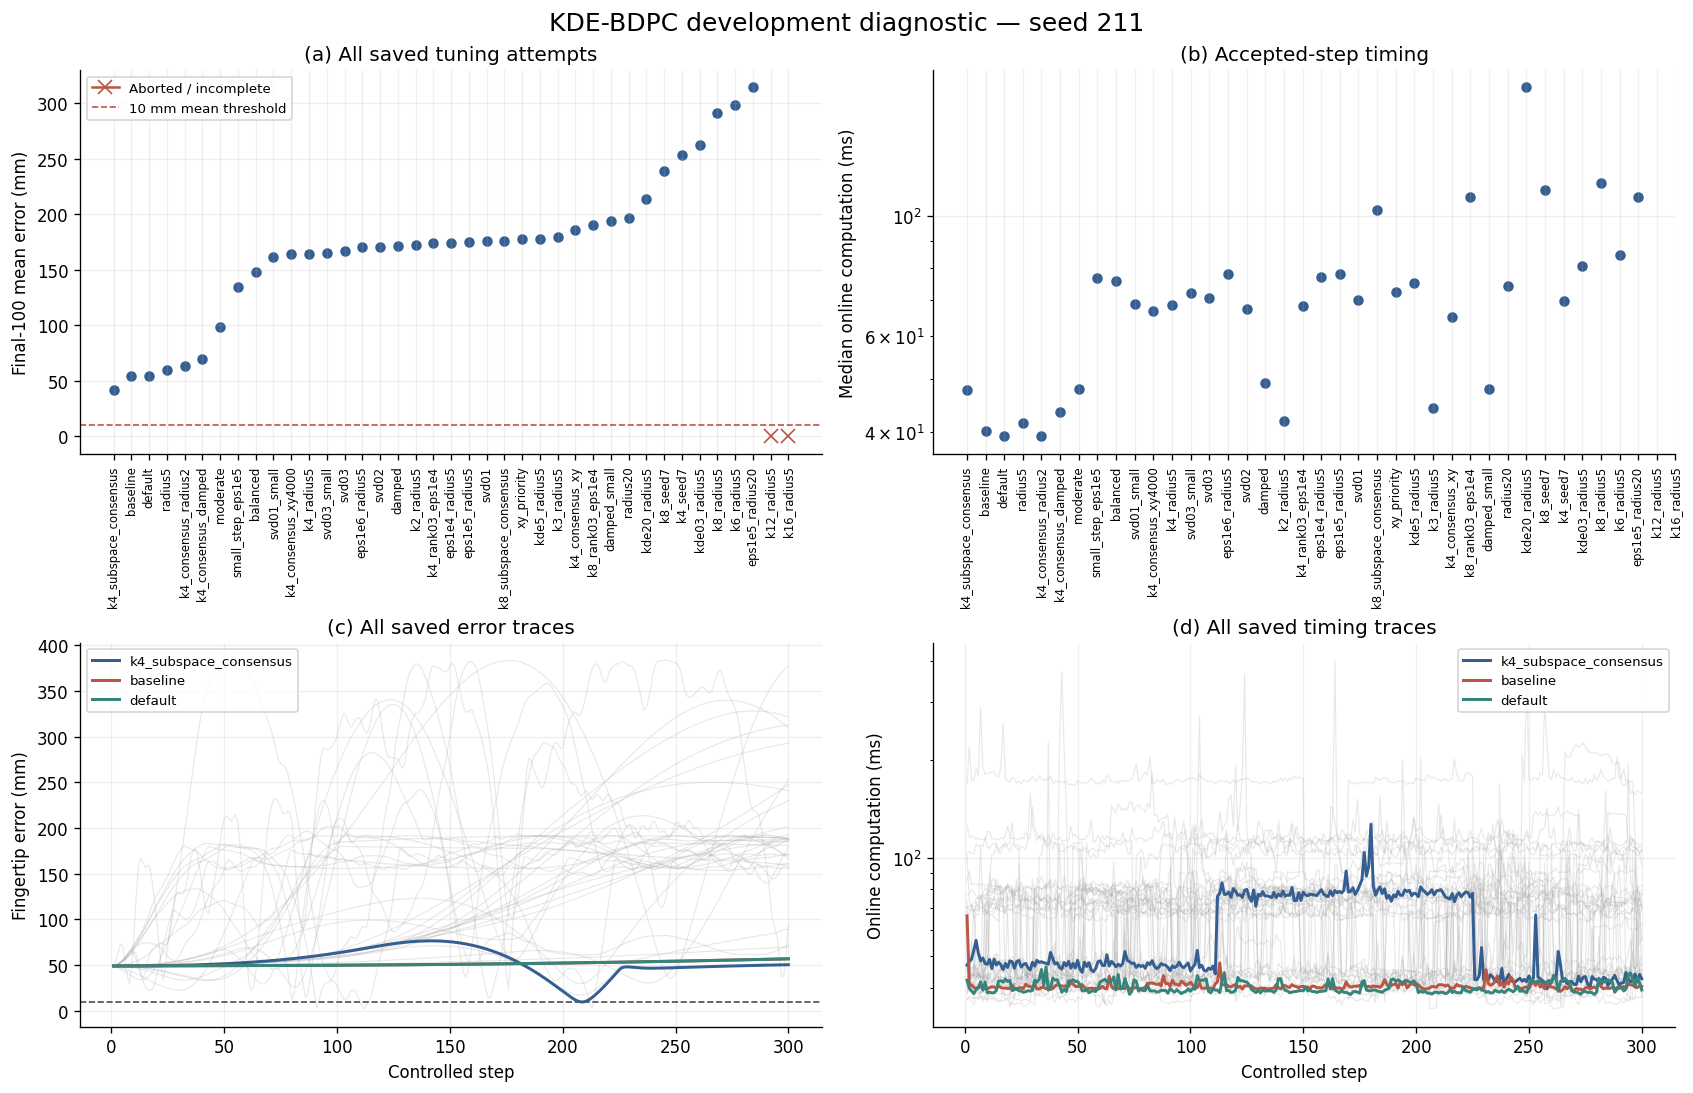

In [5]:
fig, axes = plt.subplots(2,2,figsize=(14,9),constrained_layout=True)
positions = np.arange(len(focus))
for j,r in enumerate(focus):
    if r['complete']:
        axes[0,0].scatter(j,r['mean_final100_error_mm'],color='#365f91',s=28)
    else:
        axes[0,0].plot(j,0,marker='x',color='#bb5544',ms=8,
                       label='Aborted / incomplete' if not axes[0,0].get_legend_handles_labels()[0] else None)
    if r['median_online_ms'] is not None:
        axes[0,1].scatter(j,r['median_online_ms'],color='#365f91' if r['complete'] else '#bb5544',s=28)
for ax in axes[0]:
    ax.set_xticks(positions)
    ax.set_xticklabels([r['name'] for r in focus],rotation=90,fontsize=7)
axes[0,0].axhline(10,color='#bb5544',ls='--',lw=1,label='10 mm mean threshold')
axes[0,0].set(ylabel='Final-100 mean error (mm)',title='(a) All saved tuning attempts')
axes[0,0].legend(fontsize=8)
axes[0,1].set(ylabel='Median online computation (ms)',yscale='log',title='(b) Accepted-step timing')
highlight = {r['candidate']:c for r,c in zip(complete[:3],['#365f91','#bb5544','#36857b'])}
for r in focus:
    a,b = measurements['rollout_offsets'][r['rollout_id']:r['rollout_id']+2]
    if b == a: continue
    x = np.arange(1,b-a+1)
    color = highlight.get(r['candidate'],'0.65')
    is_highlight = r['candidate'] in highlight
    kw = dict(color=color,alpha=1 if is_highlight else .25,lw=1.8 if is_highlight else .7,
              zorder=3 if is_highlight else 1,label=r['name'] if is_highlight else None)
    axes[1,0].plot(x,measurements['distance_m'][a:b]*1000,**kw)
    axes[1,1].plot(x,measurements['control_compute_time_s'][a:b]*1000,**kw)
axes[1,0].axhline(10,color='0.3',ls='--',lw=1)
axes[1,0].set(xlabel='Controlled step',ylabel='Fingertip error (mm)',title='(c) All saved error traces')
axes[1,1].set(xlabel='Controlled step',ylabel='Online computation (ms)',yscale='log',title='(d) All saved timing traces')
for ax in axes[1]: ax.legend(fontsize=8)
fig.suptitle(f'KDE-BDPC development diagnostic — seed {FOCUS_SEED}',fontsize=15)
plt.show()

## 5. Full historical record — kept separate from the fixed-seed diagnostic

All saved tuning configurations and stage protocols remain visible here. Stage reuse is not counted as a new rollout. Seed sets differ across stages: do not interpret the pooled inventory as a success-rate benchmark. The frozen 100-seed panel below is also development data, **not held-out testing**.

In [6]:
display(pd.DataFrame([report['tuning_totals']]))
with pd.option_context('display.max_rows',None,'display.max_colwidth',120):
    display(pd.DataFrame(report['stages']))
def historical_outcomes(rows):
    return pd.DataFrame([{
        'Candidate':r['candidate'], 'Seeds':r['seeds'], 'Horizons':r['requested_steps'],
        'Completed':r['full_rollouts'], 'Aborted':r['aborted_rollouts'], 'Successes':r['successes'],
        'Mean final-100 error (mm)':r['mean_final100_error_mm'],
        'Median online time (ms)':r['median_online_ms'], 'Offline failure':r['offline_failure'],
        'Recorded failures':'; '.join(r['failure_reasons'])
    } for r in rows])
with pd.option_context('display.max_rows',None,'display.max_colwidth',120):
    display(historical_outcomes(candidate_rows))
display(Markdown('### Separate 100-seed development panel'))
panel = [r for r in report['configurations'] if r['group']=='separate_100_seed_panel']
display(historical_outcomes(panel))
if panel: display(pd.DataFrame([panel[0]['config']]))

,candidate_directories,unique_configurations,saved_rollouts,full_rollouts,aborted_rollouts,offline_rejections
0,39,38,54,52,2,0


,stage,seeds,steps,candidates
0,kde_bdpc_tuning_20261101_v1/comparison4,"[211, 237, 281, 305]",300,"[default, radius5, moderate]"
1,kde_bdpc_tuning_20261101_v1/screen1,[211],300,"[radius5, radius20, eps1e4_radius5, eps1e5_radius5, eps1e6_radius5, eps1e5_radius20, balanced, xy_priority, svd03]"
2,kde_bdpc_tuning_20261101_v1/screen2,[211],300,"[small_step_eps1e5, damped, damped_small, svd01, svd02, svd03_small, svd01_small]"
3,kde_bdpc_tuning_20261101_v1/screen3,[211],300,"[kde03_radius5, kde5_radius5, kde20_radius5, moderate]"
4,kde_bdpc_cluster_tuning_20261101_v1/cluster_comparison4,"[211, 237, 281, 305]",300,"[k4_subspace_consensus, k4_consensus_radius2]"
5,kde_bdpc_cluster_tuning_20261101_v1/cluster_refinement,[211],300,"[k4_seed7, k8_seed7, k4_subspace_consensus, k8_subspace_consensus, k4_rank03_eps1e4, k8_rank03_eps1e4]"
6,kde_bdpc_cluster_tuning_20261101_v1/cluster_screen,[211],300,"[k2_radius5, k3_radius5, k4_radius5, k6_radius5, k8_radius5, k12_radius5, k16_radius5]"
7,kde_bdpc_cluster_tuning_20261101_v1/k4_control_refinement,[211],300,"[k4_consensus_radius2, k4_consensus_xy, k4_consensus_xy4000, k4_consensus_damped]"


,Candidate,Seeds,Horizons,Completed,Aborted,Successes,Mean final-100 error (mm),Median online time (ms),Offline failure,Recorded failures
0,kde_bdpc_tuning_20261101_v1/balanced,[211],[300],1,0,0,147.822470,75.923646,None,
1,kde_bdpc_tuning_20261101_v1/baseline,[211],[300],1,0,0,54.357562,40.148042,None,
2,kde_bdpc_tuning_20261101_v1/damped,[211],[300],1,0,0,171.841823,49.224250,None,
3,kde_bdpc_tuning_20261101_v1/damped_small,[211],[300],1,0,0,193.989165,48.094916,None,
4,kde_bdpc_tuning_20261101_v1/default,"[211, 237, 281, 305]",[300],4,0,0,249.540102,63.775896,None,
5,kde_bdpc_tuning_20261101_v1/eps1e4_radius5,[211],[300],1,0,0,174.331085,77.210104,None,
6,kde_bdpc_tuning_20261101_v1/eps1e5_radius20,[211],[300],1,0,0,314.333212,108.380833,None,
7,kde_bdpc_tuning_20261101_v1/eps1e5_radius5,[211],[300],1,0,0,174.737595,78.058542,None,
8,kde_bdpc_tuning_20261101_v1/eps1e6_radius5,[211],[300],1,0,0,170.221899,78.029063,None,
9,kde_bdpc_tuning_20261101_v1/kde03_radius5,[211],[300],1,0,0,262.242934,80.777167,None,


### Separate 100-seed development panel

,Candidate,Seeds,Horizons,Completed,Aborted,Successes,Mean final-100 error (mm),Median online time (ms),Offline failure,Recorded failures
0,kde_bdpc_p8_k4_consensus_dev100_t300_v1,"[211, 212, 213, 214, 215, 216, 217, 218, 219, ...",[300],100,0,0,241.592482,63.449374,None,


,past,future,warmup,clusters,lambda_view1,lambda_view2,svd_rtol,nmf_seed,nmf_tol,nmf_outer,...,r,lambda_epsilon,graph_max_steps,path_max_iter,max_simple_paths,path_tol,eigen_tol,solver_tol,solver_max_iter,accept_residual
0,2,10,12,4,0.01,1.0,0.01,42,0.000001,10000,...,0.1,100.0,64,100,100000,1.000000e-07,1.000000e-10,1.000000e-08,1000,0.00001


## 6. Scope, provenance, and interpretation

- Every number above is recomputed from saved traces. Source paths, hashes, full configurations and failure records are available in `report`; per-step measurements are in `measurements`.
- The main table is a fixed-seed development diagnostic. It cannot establish a general impossibility result for KDE-BDPC.
- This notebook makes no numerical Atlas comparison without a separately verified matched Atlas trace. Shared data and input bounds alone do not document every implementation difference.
- The available tuning inventory comprises the two recorded KDE-BDPC tuning families. Smoke tests, KDE–Atlas hybrids, and unrecorded manual trials are not counted as additional tuning evidence.
- Original experiment files and existing external-drive exports are untouched. Refreshing this notebook writes only its displayed results.

In [7]:
display(Markdown('### Exact trace sources for the fixed-seed results'))
with pd.option_context('display.max_rows',None,'display.max_colwidth',120):
    display(pd.DataFrame([{'Candidate':r['name'],'Trace path':r['trace_path'],
                           'SHA-256':r['trace_sha256']} for r in focus]))
print('Validated source files:',len(report['inventory']))
print('Original records preserved; no controller was run.')

### Exact trace sources for the fixed-seed results

,Candidate,Trace path,SHA-256
0,k4_subspace_consensus,/Volumes/Crucial X10/atlas_deepc_data/experiments/reacher/kde_bdpc_cluster_tuning_20261101_v1/k4_subspace_consensus/...,e6910f2b3976a12a798832dd5586bf0e980fb784f8888a098b11c16562ae0991
1,baseline,/Volumes/Crucial X10/atlas_deepc_data/experiments/reacher/kde_bdpc_tuning_20261101_v1/baseline/seed211_control_resul...,dda92cd7c11070e4d220b94f7b7ef5c9e4c046f99f2886b1d3d25c551dc4e7a9
2,default,/Volumes/Crucial X10/atlas_deepc_data/experiments/reacher/kde_bdpc_tuning_20261101_v1/default/seed211_control_result...,9de2a44a2a61f34cd39923841c346bf24e7da1ed44c2cc22d023f2eafeb613db
3,radius5,/Volumes/Crucial X10/atlas_deepc_data/experiments/reacher/kde_bdpc_tuning_20261101_v1/radius5/seed211_control_result...,3a2edd5694513f1a53e2af1c2443a5ec0d8a790e8c200ba50db3b4810b358d89
4,k4_consensus_radius2,/Volumes/Crucial X10/atlas_deepc_data/experiments/reacher/kde_bdpc_cluster_tuning_20261101_v1/k4_consensus_radius2/s...,7bf01408b4750c134f70a04e3ec5a93fd3592092c97d1111177d8fedf0edfe11
5,k4_consensus_damped,/Volumes/Crucial X10/atlas_deepc_data/experiments/reacher/kde_bdpc_cluster_tuning_20261101_v1/k4_consensus_damped/se...,546ccd03aca886910ab47d8be17ede03fa0b2460ce36c76d01e86d98dd976dd0
6,moderate,/Volumes/Crucial X10/atlas_deepc_data/experiments/reacher/kde_bdpc_tuning_20261101_v1/moderate/seed211_control_resul...,96294c18f5c1430de2938fbb7384217dc9e4fe0a21e405dc837e4fb7774c55ac
7,small_step_eps1e5,/Volumes/Crucial X10/atlas_deepc_data/experiments/reacher/kde_bdpc_tuning_20261101_v1/small_step_eps1e5/seed211_cont...,7e521fbe9e49e5f25c8589ef89a484b1f1eed5b64dfa1b7571f14ef53176d918
8,balanced,/Volumes/Crucial X10/atlas_deepc_data/experiments/reacher/kde_bdpc_tuning_20261101_v1/balanced/seed211_control_resul...,d37a8031d625ab483a52eddc429eb656ea77eae3fdc02973e9236d6cbfa23f2f
9,svd01_small,/Volumes/Crucial X10/atlas_deepc_data/experiments/reacher/kde_bdpc_tuning_20261101_v1/svd01_small/seed211_control_re...,607fade9140d9cf667dbd7990bbdf2bf625362708bde1e3f4310758a5490917b


Validated source files: 242
Original records preserved; no controller was run.
